In [1]:
!pip install pandas
!pip install numpy
!pip install seaborn
!pip install numpy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [106]:
#import libraries

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

In [3]:
import pandas as pd
df_patient = pd.read_csv('patient.csv')

In [4]:
print("Rows:", df_patient.shape[0])
print("Columns:", df_patient.shape[1])

Rows: 200859
Columns: 29


In [5]:
print(df_patient.columns.tolist())

['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']


In [6]:
print(df_patient.dtypes)

patientunitstayid              int64
patienthealthsystemstayid      int64
gender                           str
age                              str
ethnicity                        str
hospitalid                     int64
wardid                         int64
apacheadmissiondx                str
admissionheight              float64
hospitaladmittime24              str
hospitaladmitoffset            int64
hospitaladmitsource              str
hospitaldischargeyear          int64
hospitaldischargetime24          str
hospitaldischargeoffset        int64
hospitaldischargelocation        str
hospitaldischargestatus          str
unittype                         str
unitadmittime24                  str
unitadmitsource                  str
unitvisitnumber                int64
unitstaytype                     str
admissionweight              float64
dischargeweight              float64
unitdischargetime24              str
unitdischargeoffset            int64
unitdischargelocation            str
u

df_patient.info()

Missing Values Analysis

In [7]:
missing = df_patient.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

dischargeweight              90937
hospitaladmitsource          49464
apacheadmissiondx            22996
admissionweight              16718
admissionheight               4215
ethnicity                     2290
hospitaldischargelocation     2033
hospitaldischargestatus       1751
unitadmitsource               1090
unitdischargelocation          334
gender                         134
age                             95
unitdischargestatus             34
dtype: int64


In [8]:
#Missing Percentage

In [9]:
missing_pct = (
    df_patient.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_pct[missing_pct > 0])

dischargeweight              45.274048
hospitaladmitsource          24.626230
apacheadmissiondx            11.448827
admissionweight               8.323252
admissionheight               2.098487
ethnicity                     1.140103
hospitaldischargelocation     1.012153
hospitaldischargestatus       0.871756
unitadmitsource               0.542669
unitdischargelocation         0.166286
gender                        0.066713
age                           0.047297
unitdischargestatus           0.016927
dtype: float64


Target Distribution

In [10]:
# ICU Mortality

print(
    df_patient['unitdischargestatus']
    .value_counts()
)

unitdischargestatus
Alive      189918
Expired     10907
Name: count, dtype: int64


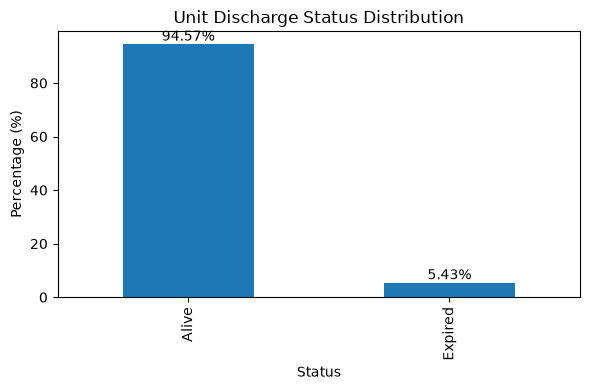

In [11]:
import matplotlib.pyplot as plt

# Unit discharge status
unit_pct = (
    df_patient['unitdischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,4))
ax = unit_pct.plot(kind='bar')

plt.title('Unit Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

for i, v in enumerate(unit_pct):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [12]:
# Hospital Discharge Status

print(
    df_patient['hospitaldischargestatus']
    .value_counts()
)

hospitaldischargestatus
Alive      181104
Expired     18004
Name: count, dtype: int64


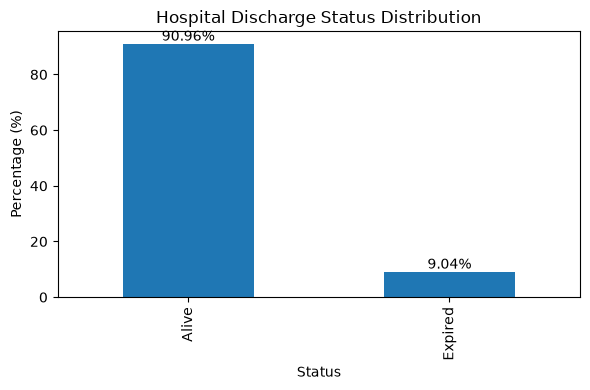

In [13]:
import matplotlib.pyplot as plt

# Hospital discharge status
hospital_pct = (
    df_patient['hospitaldischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,4))
ax = hospital_pct.plot(kind='bar')

plt.title('Hospital Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

for i, v in enumerate(hospital_pct):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

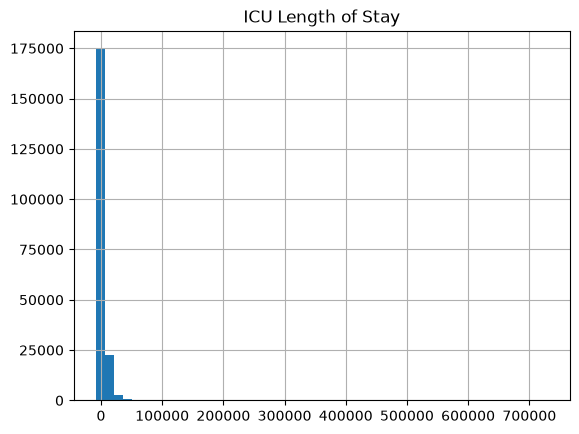

count    200859.000000
mean          2.679258
std           4.330865
min          -5.338194
25%           0.818750
50%           1.573611
75%           2.971528
max         506.372222
Name: unitdischargeoffset, dtype: float64

In [14]:
# ICU Length of Stay

df_patient['unitdischargeoffset'].hist(
    bins=50
)

plt.title('ICU Length of Stay')
plt.show()

los_days = (
    df_patient['unitdischargeoffset']
    / 1440
)

los_days.describe()

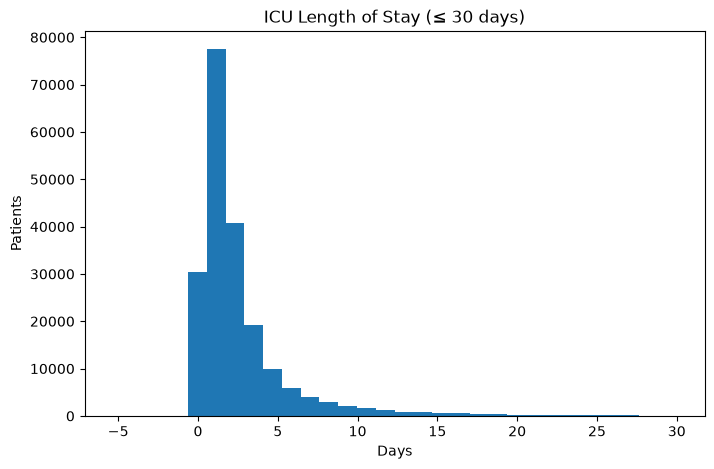

In [15]:
import matplotlib.pyplot as plt

los_days = df_patient['unitdischargeoffset'] / 1440

plt.figure(figsize=(8,5))
plt.hist(los_days[los_days <= 30], bins=30)

plt.title('ICU Length of Stay (≤ 30 days)')
plt.xlabel('Days')
plt.ylabel('Patients')

plt.show()

Hospital Distribution

In [16]:
print(
    df_patient['hospitalid']
    .nunique()
)

208


In [17]:
df_patient['hospitalid'] \
    .value_counts() \
    .head(20)

hospitalid
73     7059
167    6092
264    5237
420    4679
176    4328
338    4277
243    4243
199    4240
458    3701
443    3656
208    3650
300    3617
188    3601
252    3371
411    3199
165    3053
122    2941
148    2881
171    2807
281    2531
Name: count, dtype: int64

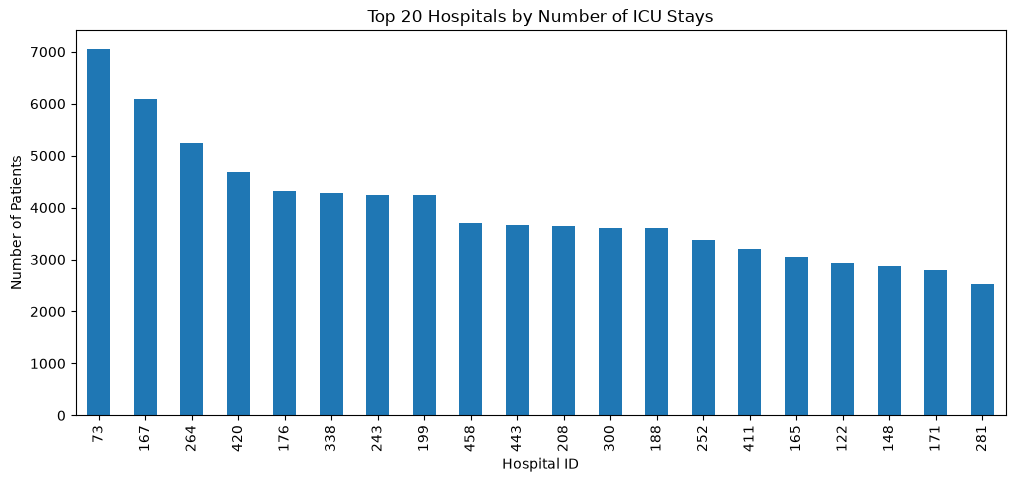

In [18]:
import matplotlib.pyplot as plt

hospital_counts = (
    df_patient['hospitalid']
    .value_counts()
)

plt.figure(figsize=(12,5))

hospital_counts.head(20).plot(kind='bar')

plt.title('Top 20 Hospitals by Number of ICU Stays')
plt.xlabel('Hospital ID')
plt.ylabel('Number of Patients')

plt.show()

In [19]:
print(
    "Hospitals:",
    df_patient['hospitalid'].nunique()
)

print(
    "ICU types:",
    df_patient['unittype'].value_counts()
)

# print(
#     "Regions:",
#     df_patient['region'].value_counts()
# )

Hospitals: 208
ICU types: unittype
Med-Surg ICU    113222
MICU             17465
CCU-CTICU        15290
Neuro ICU        14451
Cardiac ICU      12467
SICU             12181
CSICU             9625
CTICU             6158
Name: count, dtype: int64


Numerical columns → Median imputation

In [20]:
#df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = pd.to_numeric(
    df_patient['age'],
    errors='coerce'
)

In [21]:
df_patient['admissionweight'] = (
    df_patient['admissionweight']
    .fillna(df_patient['admissionweight'].median())
)

df_patient['admissionheight'] = (
    df_patient['admissionheight']
    .fillna(df_patient['admissionheight'].median())
)

df_patient['age'] = (
    df_patient['age']
    .fillna(df_patient['age'].median())
)

In [22]:
print(df_patient['age'].dtype)

print(df_patient['age'].head(20))

print(df_patient['age'].unique()[:20])

float64
0     70.0
1     52.0
2     52.0
3     68.0
4     71.0
5     71.0
6     77.0
7     25.0
8     82.0
9     90.0
10    81.0
11    59.0
12    43.0
13    19.0
14    19.0
15    67.0
16    73.0
17    59.0
18    63.0
19    61.0
Name: age, dtype: float64
[70. 52. 68. 71. 77. 25. 82. 90. 81. 59. 43. 19. 67. 73. 63. 61. 45. 76.
 50. 72.]


In [23]:
df_patient['uniquepid'].nunique()


139367

In [24]:
df_patient['patienthealthsystemstayid'].nunique()

166355

In [25]:
df_patient.columns.tolist()

['patientunitstayid',
 'patienthealthsystemstayid',
 'gender',
 'age',
 'ethnicity',
 'hospitalid',
 'wardid',
 'apacheadmissiondx',
 'admissionheight',
 'hospitaladmittime24',
 'hospitaladmitoffset',
 'hospitaladmitsource',
 'hospitaldischargeyear',
 'hospitaldischargetime24',
 'hospitaldischargeoffset',
 'hospitaldischargelocation',
 'hospitaldischargestatus',
 'unittype',
 'unitadmittime24',
 'unitadmitsource',
 'unitvisitnumber',
 'unitstaytype',
 'admissionweight',
 'dischargeweight',
 'unitdischargetime24',
 'unitdischargeoffset',
 'unitdischargelocation',
 'unitdischargestatus',
 'uniquepid']

In [26]:
icu_per_patient = (
    df_patient.groupby('uniquepid')['patientunitstayid']
              .nunique()
              .reset_index()
)

icu_per_patient.columns = [
    'uniquepid',
    'icu_stay_count'
]

icu_per_patient.head(20)

,uniquepid,icu_stay_count
0,002-10009,1
1,002-10018,1
2,002-10034,1
3,002-10050,3
4,002-10052,1
5,002-10063,1
6,002-10066,1
7,002-10067,1
8,002-1007,1
9,002-10076,2


Missing Value Analysis

In [27]:
missing_values = pd.DataFrame({
    'missing_count': df_patient.isnull().sum(),
    'missing_percentage': (
        df_patient.isnull().sum() / len(df_patient) * 100
    ).round(2),
    'dtype': df_patient.dtypes
})

missing_values = missing_values.sort_values(
    'missing_percentage',
    ascending=False
)

missing_values

,missing_count,missing_percentage,dtype
dischargeweight,90937,45.27,float64
hospitaladmitsource,49464,24.63,str
apacheadmissiondx,22996,11.45,str
ethnicity,2290,1.14,str
hospitaldischargelocation,2033,1.01,str
hospitaldischargestatus,1751,0.87,str
unitadmitsource,1090,0.54,str
unitdischargelocation,334,0.17,str
gender,134,0.07,str
unitdischargestatus,34,0.02,str


# Dataset Preprocessing

admissionweight	8.32%	Median imputation

admissionheight	2.10%	Median imputation

In [28]:
df_patient['admissionweight'] = (
    df_patient['admissionweight']
    .fillna(df_patient['admissionweight'].median())
)

df_patient['admissionheight'] = (
    df_patient['admissionheight']
    .fillna(df_patient['admissionheight'].median())
)

In [29]:
categorical_cols = [
    'hospitaladmitsource',
    'apacheadmissiondx',
    'ethnicity',
    'unitadmitsource',
    'gender'
]

for col in categorical_cols:
    df_patient[col] = df_patient[col].fillna('Unknown')

In [30]:
df_patient['age'].value_counts(dropna=False).head(20)

age
90.0    7081
67.0    5078
68.0    4826
72.0    4804
71.0    4764
65.0    4744
66.0    4677
70.0    4571
63.0    4460
62.0    4355
73.0    4333
64.0    4318
69.0    4301
75.0    4280
60.0    4217
61.0    4197
76.0    4170
74.0    4126
77.0    4110
59.0    4068
Name: count, dtype: int64

In [31]:
df_patient['age'] = (
    df_patient['age']
    .replace('> 89', 90)
)

In [32]:
df_patient['apacheadmissiondx'].nunique()

393

Most Common Diagnosis

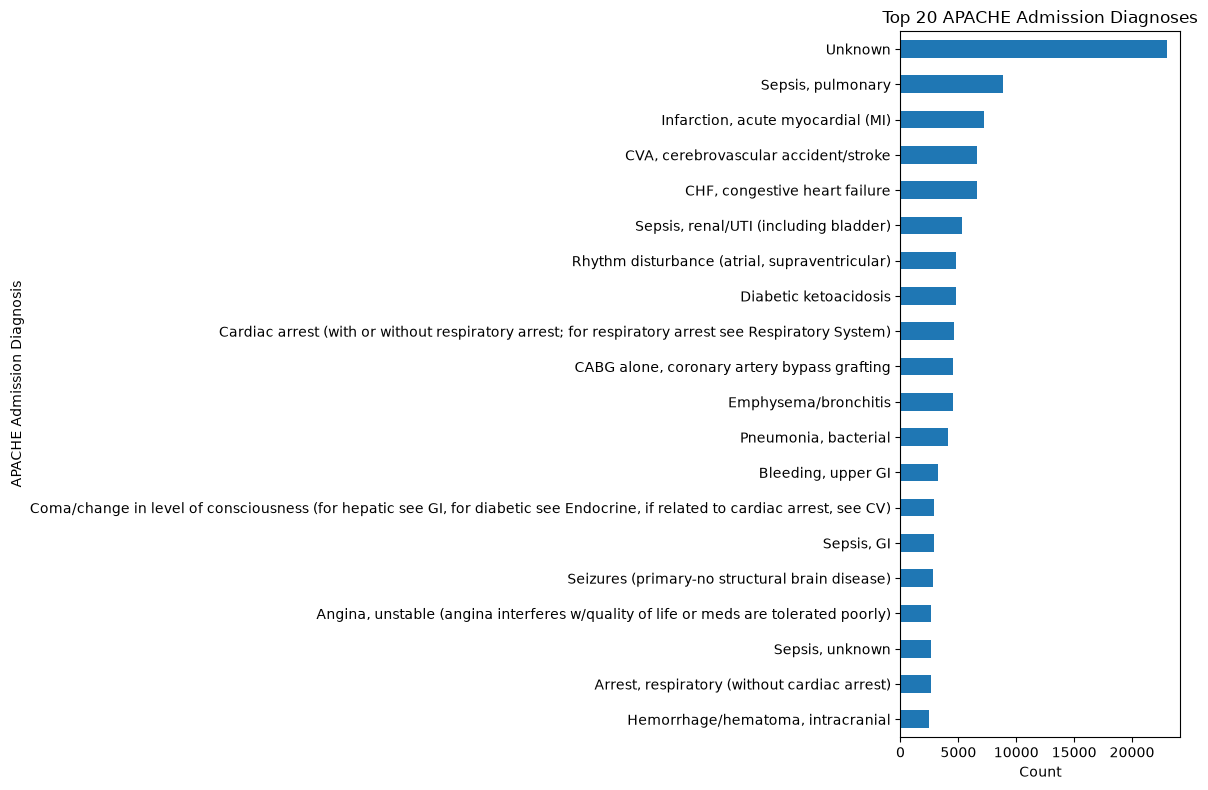

In [33]:
top_dx = (
    df_patient['apacheadmissiondx']
    .value_counts()
    .head(20)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
top_dx.sort_values().plot(kind='barh')

plt.xlabel('Count')
plt.ylabel('APACHE Admission Diagnosis')
plt.title('Top 20 APACHE Admission Diagnoses')

plt.tight_layout()
plt.show()

In [34]:
top_dx = (
    df_patient['apacheadmissiondx']
    .value_counts()
    .head(20)
    .reset_index()
)

top_dx.columns = ['Diagnosis', 'Count']

print(top_dx)

                                            Diagnosis  Count
0                                             Unknown  22996
1                                   Sepsis, pulmonary   8862
2                   Infarction, acute myocardial (MI)   7228
3                CVA, cerebrovascular accident/stroke   6647
4                       CHF, congestive heart failure   6617
5               Sepsis, renal/UTI (including bladder)   5273
6       Rhythm disturbance (atrial, supraventricular)   4827
7                               Diabetic ketoacidosis   4825
8   Cardiac arrest (with or without respiratory ar...   4580
9         CABG alone, coronary artery bypass grafting   4543
10                               Emphysema/bronchitis   4494
11                               Pneumonia, bacterial   4101
12                                 Bleeding, upper GI   3238
13  Coma/change in level of consciousness (for hep...   2902
14                                         Sepsis, GI   2881
15     Seizures (primary

# Mortality rate per diagnosis.

In [35]:
df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [36]:
mortality_by_dx = (
    df_patient
    .groupby('apacheadmissiondx')['target']
    .agg(['count', 'mean'])
    .sort_values('count', ascending=False)
)

mortality_by_dx.head(20)

,count,mean
apacheadmissiondx,,
Unknown,22996,0.030092
"Sepsis, pulmonary",8862,0.120515
"Infarction, acute myocardial (MI)",7228,0.030576
"CVA, cerebrovascular accident/stroke",6647,0.049797
"CHF, congestive heart failure",6617,0.053952
"Sepsis, renal/UTI (including bladder)",5273,0.062773
"Rhythm disturbance (atrial, supraventricular)",4827,0.029004
Diabetic ketoacidosis,4825,0.003523
Cardiac arrest (with or without respiratory arrest; for respiratory arrest see Respiratory System),4580,0.414847


In [37]:
mortality_by_dx = (
    df_patient
    .groupby('apacheadmissiondx')['target']
    .agg(['count', 'mean'])
    .reset_index()
)

mortality_by_dx['mortality_percent'] = (
    mortality_by_dx['mean'] * 100
).round(2)

mortality_by_dx = mortality_by_dx[
    mortality_by_dx['count'] >= 100
]

mortality_by_dx.sort_values(
    'mortality_percent',
    ascending=False
).head(20)

,apacheadmissiondx,count,mean,mortality_percent
89,Cardiac arrest (with or without respiratory ar...,4580,0.414847,41.48
337,"Shock, cardiogenic",550,0.223636,22.36
76,"Cancer, lung",364,0.173077,17.31
210,"Hemorrhage/hematoma-intracranial, surgery for",180,0.166667,16.67
26,"Aneurysm, thoracic aortic; with dissection",138,0.166667,16.67
175,"GI vascular ischemia, surgery for (resection)",211,0.156398,15.64
330,"Sepsis, GI",2881,0.135717,13.57
213,"Hepatic failure, acute",378,0.129630,12.96
37,"Arrest, respiratory (without cardiac arrest)",2599,0.126972,12.70
209,"Hemorrhage/hematoma, intracranial",2450,0.122449,12.24


In [38]:
# Age values
df_patient['age'].value_counts(dropna=False).head(20)

# Gender distribution
df_patient['gender'].value_counts(dropna=False)

# Ethnicity distribution
df_patient['ethnicity'].value_counts(dropna=False)

# ICU mortality distribution
df_patient['unitdischargestatus'].value_counts(dropna=False)

unitdischargestatus
Alive      189918
Expired     10907
NaN            34
Name: count, dtype: int64

In [39]:
# Age values
df_patient['age'].value_counts(dropna=False).head(20)

# Gender distribution
df_patient['gender'].value_counts(dropna=False)

# Ethnicity distribution
df_patient['ethnicity'].value_counts(dropna=False)

# ICU mortality distribution
df_patient['unitdischargestatus'].value_counts(dropna=False)

unitdischargestatus
Alive      189918
Expired     10907
NaN            34
Name: count, dtype: int64

In [40]:
# Create Target Variable

df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [41]:
df_patient['target'].value_counts()

target
0    189952
1     10907
Name: count, dtype: int64

In [42]:
df_hospital = pd.read_csv('hospital.csv')

In [43]:
print("Rows:", df_hospital.shape[0])
print("Columns:", df_hospital.shape[1])

Rows: 208
Columns: 4


In [44]:
print(df_hospital.head(10))

   hospitalid numbedscategory teachingstatus   region
0          56            <100              f  Midwest
1          58       100 - 249              f  Midwest
2          59            <100              f  Midwest
3          60            <100              f  Midwest
4          61            <100              f  Midwest
5          63       100 - 249              f  Midwest
6          66       100 - 249              f  Midwest
7          67             NaN              f  Midwest
8          68            <100              f  Midwest
9          69            <100              f  Midwest


# How many hospitals per region

Region

   ↓

Hospitals in that region

   ↓

ICU stays (patientunitstayid) handled by those hospitals

In [45]:
# Hospitals per region

In [46]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .unique()
)

print(region_hospitals)

region
Midwest      [56, 58, 59, 60, 61, 63, 66, 67, 68, 69, 71, 7...
Northeast    [199, 200, 202, 204, 205, 206, 419, 420, 421, ...
South        [110, 112, 115, 120, 122, 123, 125, 131, 133, ...
West         [146, 148, 151, 152, 154, 155, 156, 157, 158, ...
Name: hospitalid, dtype: object


In [47]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .nunique()
)

print(region_hospitals)

region
Midwest      70
Northeast    13
South        56
West         43
Name: hospitalid, dtype: int64


In [48]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .nunique()
    .reset_index(name='num_hospitals')
)

print(region_hospitals)

      region  num_hospitals
0    Midwest             70
1  Northeast             13
2      South             56
3       West             43


In [49]:
# Count ICU stays for each region

In [50]:
region_icu_stays = []

for region in df_hospital['region'].unique():

    hospital_ids = df_hospital.loc[
        df_hospital['region'] == region,
        'hospitalid'
    ]

    icu_stays = df_patient.loc[
        df_patient['hospitalid'].isin(hospital_ids),
        'patientunitstayid'
    ].nunique()

    region_icu_stays.append([
        region,
        len(hospital_ids),
        icu_stays
    ])

region_icu_stays = pd.DataFrame(
    region_icu_stays,
    columns=[
        'region',
        'num_hospitals',
        'icu_stays'
    ]
)

print(region_icu_stays)

      region  num_hospitals  icu_stays
0    Midwest             70      65950
1        NaN              0          0
2      South             56      60294
3       West             43      46348
4  Northeast             13      14429


In [51]:
df_hospital = df_hospital.dropna(subset=['region'])

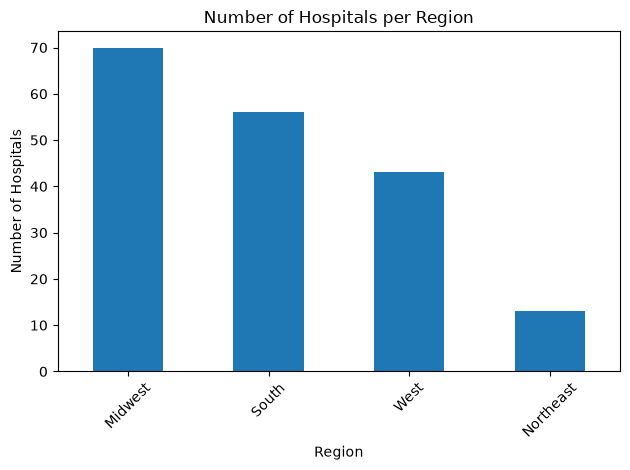

In [52]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .nunique()
    .sort_values(ascending=False)
)

region_hospitals.plot(kind='bar')

plt.title("Number of Hospitals per Region")
plt.xlabel("Region")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

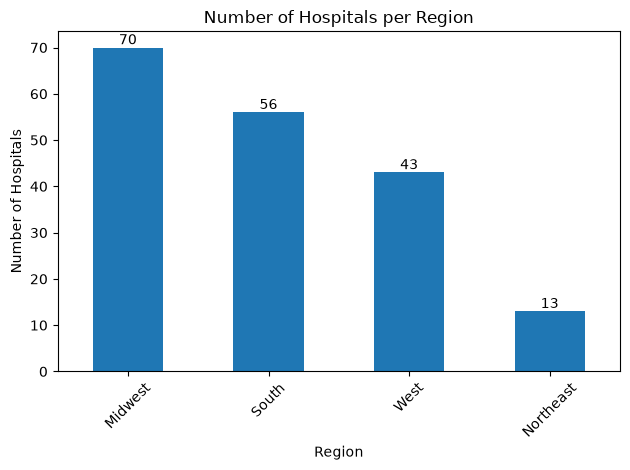

In [53]:
region_hospitals = (
    df_hospital
    .groupby('region')['hospitalid']
    .nunique()
    .sort_values(ascending=False)
)

ax = region_hospitals.plot(kind='bar')

# Add values on top of bars
for i, value in enumerate(region_hospitals):
    ax.text(
        i,              # x position
        value,          # y position
        str(value),     # label
        ha='center',
        va='bottom'
    )

plt.title("Number of Hospitals per Region")
plt.xlabel("Region")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

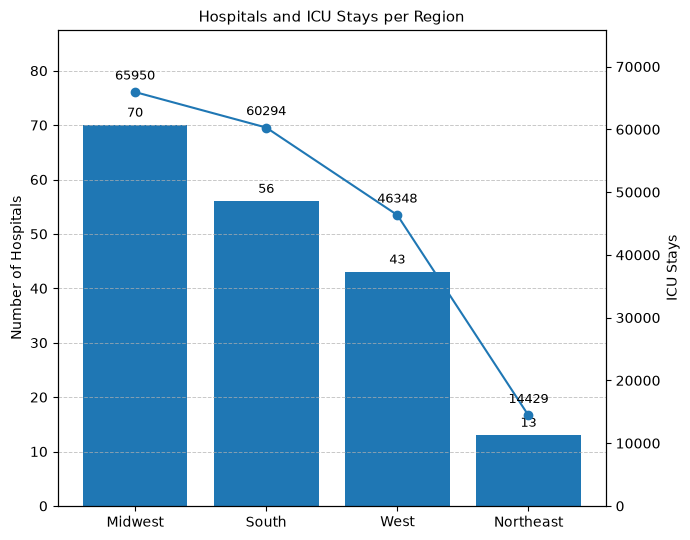

In [54]:
import matplotlib.pyplot as plt

# Data
regions = ["Midwest", "South", "West", "Northeast"]
num_hospitals = [70, 56, 43, 13]
icu_stays = [65950, 60294, 46348, 14429]

# Figure
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
fig, ax1 = plt.subplots(figsize=(7, 5.5))

# --- Bars: Hospitals ---
bars = ax1.bar(regions, num_hospitals)
ax1.set_ylabel("Number of Hospitals")
ax1.set_ylim(0, max(num_hospitals) * 1.25)  # headroom for hospital labels

# Annotate hospitals
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2,
             h + 1,
             f"{int(h)}",
             ha='center',
             va='bottom',
             fontsize=9)

# --- Line: ICU stays ---
ax2 = ax1.twinx()
ax2.plot(regions, icu_stays, marker='o', linewidth=1.5)
ax2.set_ylabel("ICU Stays")
ax2.set_ylim(0, max(icu_stays) * 1.15)  # headroom so top label isn't cut off

# Annotate ICU values
for i, v in enumerate(icu_stays):
    ax2.text(i, v + 1500,
             f"{v}",
             ha='center',
             va='bottom',
             fontsize=9,
             clip_on=False)

# --- Title ---
plt.title("Hospitals and ICU Stays per Region")

# --- Clean layout ---
ax1.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.7)
fig.tight_layout()
plt.show()

In [55]:
hospital_stats = (
    df_patient
    .groupby('hospitalid')
    .agg(
        icu_stays=('patientunitstayid','nunique'),
        patients=('uniquepid','nunique'),
        mortality=('target','mean')
    )
    .reset_index()
)

In [56]:
print(hospital_stats)

     hospitalid  icu_stays  patients  mortality
0            56        325       207   0.015385
1            58        321       231   0.015576
2            59        854       463   0.005855
3            60        458       257   0.015284
4            61        233       150   0.021459
..          ...        ...       ...        ...
203         447         39        35   0.076923
204         449       2110      1790   0.075829
205         452        874       713   0.090389
206         458       3701      3010   0.090516
207         459        592       497   0.054054

[208 rows x 4 columns]


In [57]:
# Select top 50 hospitals

In [58]:
top50_hospitals = (
    hospital_stats
    .sort_values(
        'icu_stays',
        ascending=False
    )
    .head(50)
)

selected_hospitals = (
    top50_hospitals['hospitalid']
    .tolist()
)

print(
    "Number of hospitals:",
    len(selected_hospitals)
)

Number of hospitals: 50


In [59]:
# Filter patient data

In [60]:
df_fl = df_patient[
    df_patient['hospitalid']
    .isin(selected_hospitals)
].copy()

In [61]:
print(
    "Hospitals:",
    df_fl['hospitalid'].nunique()
)

print(
    "ICU stays:",
    df_fl['patientunitstayid'].nunique()
)

Hospitals: 50
ICU stays: 132534


In [62]:
# Check class balance per client

In [63]:
client_stats = (
    df_fl
    .groupby('hospitalid')
    ['target']
    .agg(
        patients='count',
        deaths='sum',
        mortality_rate='mean'
    )
)

client_stats.head()

,patients,deaths,mortality_rate
hospitalid,,,
63,1826,49,0.026835
73,7059,227,0.032158
79,1313,98,0.074638
110,2019,124,0.061417
122,2941,248,0.084325


hospitalid-----patients

    |            |    
    
   73  --------------------7059

means:

Hospital 73 handled 7059 ICU stays

NOT:

7059 unique patients

because one patient can have multiple ICU admissions.

In [64]:
print(df_fl.head(20))

    patientunitstayid  patienthealthsystemstayid  gender   age  \
3              141194                     128941    Male  68.0   
7              141208                     128952  Female  25.0   
9              141229                     128970  Female  90.0   
10             141233                     128973  Female  81.0   
11             141244                     128982    Male  59.0   
12             141260                     128995  Female  43.0   
15             141265                     128999    Male  67.0   
17             141276                     129009  Female  59.0   
18             141284                     129017    Male  63.0   
21             141296                     129026    Male  63.0   
22             141297                     129026    Male  63.0   
24             141313                     129039    Male  45.0   
25             141314                     129039    Male  45.0   
26             141328                     129050  Female  76.0   
27        

# Data Preprocessing

In [65]:
missing_values = pd.DataFrame({
    'missing_count': df_fl.isnull().sum(),
    'missing_percentage': (
        df_fl.isnull().sum() / len(df_fl) * 100
    ).round(2),
    'dtype': df_fl.dtypes
})

missing_values = missing_values.sort_values(
    'missing_percentage',
    ascending=False
)

missing_values

,missing_count,missing_percentage,dtype
dischargeweight,52972,39.97,float64
hospitaldischargelocation,1062,0.80,str
hospitaldischargestatus,931,0.70,str
unitdischargelocation,194,0.15,str
unitdischargestatus,22,0.02,str
patientunitstayid,0,0.00,int64
wardid,0,0.00,int64
apacheadmissiondx,0,0.00,str
admissionheight,0,0.00,float64
patienthealthsystemstayid,0,0.00,int64


In [66]:
# Create FL dataset with only required columns

In [67]:
features = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitvisitnumber',
    'unitstaytype'
]

In [68]:
fl_cols = features + [
    'target',
    'hospitalid',
    'uniquepid',
    'patientunitstayid'
]

df_fl = df_fl[fl_cols].copy()

print(df_fl.shape)
print(df_fl.columns)

(132534, 16)
Index(['gender', 'age', 'ethnicity', 'apacheadmissiondx', 'admissionheight',
       'admissionweight', 'hospitaladmitoffset', 'hospitaladmitsource',
       'unittype', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype',
       'target', 'hospitalid', 'uniquepid', 'patientunitstayid'],
      dtype='str')


In [69]:
print(df_fl.shape)

print(
    df_fl['hospitalid']
    .nunique()
)

print(
    df_fl['target']
    .value_counts()
)

(132534, 16)
50
target
0    125078
1      7456
Name: count, dtype: int64


In [70]:
df_fl[features].isnull().sum()

gender                 0
age                    0
ethnicity              0
apacheadmissiondx      0
admissionheight        0
admissionweight        0
hospitaladmitoffset    0
hospitaladmitsource    0
unittype               0
unitadmitsource        0
unitvisitnumber        0
unitstaytype           0
dtype: int64

In [71]:
print(df_fl)

        gender   age         ethnicity  \
3         Male  68.0         Caucasian   
7       Female  25.0         Caucasian   
9       Female  90.0         Caucasian   
10      Female  81.0         Caucasian   
11        Male  59.0         Caucasian   
...        ...   ...               ...   
200853  Female  79.0  African American   
200854    Male  50.0         Caucasian   
200855  Female  79.0         Caucasian   
200856    Male  73.0  African American   
200858    Male  35.0  African American   

                                        apacheadmissiondx  admissionheight  \
3                   Sepsis, renal/UTI (including bladder)            180.3   
7       Overdose, sedatives, hypnotics, antipsychotics...            172.7   
9                           CHF, congestive heart failure            160.0   
10                               Mitral valve replacement            165.1   
11                        Graft, femoral-popliteal bypass            180.3   
...                        

In [72]:
features = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitvisitnumber',
    'unitstaytype'
]

df_fl_final = df_fl[
    features
].copy()

print(df_fl_final.shape)
print(df_fl_final.head())

(132534, 12)
    gender   age  ethnicity  \
3     Male  68.0  Caucasian   
7   Female  25.0  Caucasian   
9   Female  90.0  Caucasian   
10  Female  81.0  Caucasian   
11    Male  59.0  Caucasian   

                                    apacheadmissiondx  admissionheight  \
3               Sepsis, renal/UTI (including bladder)            180.3   
7   Overdose, sedatives, hypnotics, antipsychotics...            172.7   
9                       CHF, congestive heart failure            160.0   
10                           Mitral valve replacement            165.1   
11                    Graft, femoral-popliteal bypass            180.3   

    admissionweight  hospitaladmitoffset   hospitaladmitsource      unittype  \
3              73.9                 -780                 Floor         CTICU   
7              95.3                   -1  Emergency Department  Med-Surg ICU   
9              89.8                   -4  Emergency Department  Med-Surg ICU   
10             61.7                

In [73]:
X = df_fl_final.copy()

y = df_fl['target']

In [74]:
# Creating Clients

# Each 50 hopitals will be treated as 50 clients

In [75]:
hospital_list = sorted(
    df_fl['hospitalid'].unique()
)

hospital_to_client = {
    hospital: idx + 1
    for idx, hospital in enumerate(hospital_list)
}

In [76]:
print(
    list(hospital_to_client.items())[:10]
)

[(np.int64(63), 1), (np.int64(73), 2), (np.int64(79), 3), (np.int64(110), 4), (np.int64(122), 5), (np.int64(141), 6), (np.int64(142), 7), (np.int64(146), 8), (np.int64(148), 9), (np.int64(152), 10)]


In [77]:
# Create client IDs

In [78]:
df_fl['client_id'] = (
    df_fl['hospitalid']
    .map(hospital_to_client)
)

In [79]:
print(
    df_fl[['hospitalid', 'client_id']]
    .drop_duplicates()
    .head(10)
)

       hospitalid  client_id
3              73          2
9              63          1
14985          79          3
17813         110          4
17816         122          5
24358         142          7
24364         141          6
29808         165         13
29810         152         10
29811         167         14


In [80]:
mapping_table = (
    df_fl[['hospitalid', 'client_id']]
    .drop_duplicates()
    .sort_values('client_id')
)

print(mapping_table)

        hospitalid  client_id
9               63          1
3               73          2
14985           79          3
17813          110          4
17816          122          5
24364          141          6
24358          142          7
29839          146          8
29818          148          9
29810          152         10
29816          154         11
29824          157         12
29808          165         13
29811          167         14
29813          171         15
29827          176         16
58789          183         17
63630          188         18
67232          197         19
71615          199         20
79278          208         21
87513          227         22
90294          243         23
96461          248         24
96457          252         25
102868         264         26
111179         277         27
111160         281         28
111164         283         29
123978         300         30
123976         307         31
123984         310         32
123981    

# EDA of Federated Setting

In [81]:
client_sizes = (
    df_fl
    .groupby('client_id')
    .size()
    .reset_index(name='records')
    .sort_values(
        'records',
        ascending=False
    )
)

print(client_sizes)

    client_id  records
1           2     7059
13         14     6092
25         26     5237
43         44     4679
15         16     4328
34         35     4277
22         23     4243
19         20     4240
49         50     3701
46         47     3656
20         21     3650
29         30     3617
17         18     3601
24         25     3371
39         40     3199
12         13     3053
4           5     2941
8           9     2881
14         15     2807
27         28     2531
40         41     2411
16         17     2135
48         49     2110
45         46     2102
28         29     2097
11         12     2092
33         34     2086
41         42     2078
3           4     2019
42         43     1960
37         38     1937
10         11     1875
30         31     1853
0           1     1826
18         19     1814
6           7     1782
35         36     1758
9          10     1747
23         24     1678
7           8     1612
36         37     1596
5           6     1568
21         

Top 15 clients with the most records

In [82]:
top15_clients = (
    client_sizes
    .head(15)
)

print(top15_clients)

    client_id  records
1           2     7059
13         14     6092
25         26     5237
43         44     4679
15         16     4328
34         35     4277
22         23     4243
19         20     4240
49         50     3701
46         47     3656
20         21     3650
29         30     3617
17         18     3601
24         25     3371
39         40     3199


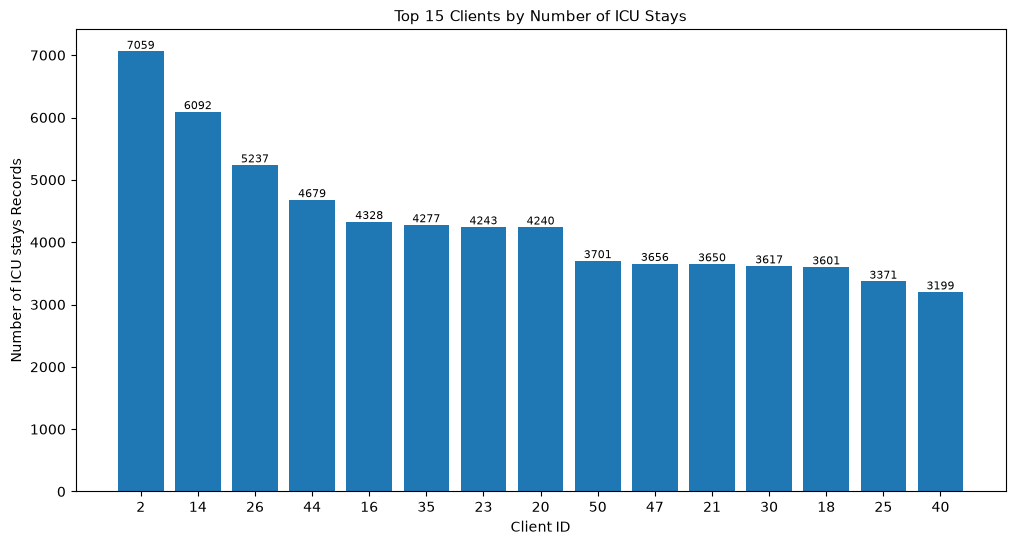

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

bars = plt.bar(
    top15_clients['client_id'].astype(str),
    top15_clients['records']
)

plt.title('Top 15 Clients by Number of ICU Stays')
plt.xlabel('Client ID')
plt.ylabel('Number of ICU stays Records')

# Add values on top
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.show()

In [84]:
hospital_stats[
    hospital_stats['hospitalid'] == 73
]

,hospitalid,icu_stays,patients,mortality
11,73,7059,4511,0.032158


Create Alive vs Expired counts per client

In [85]:
client_class_dist = (
    df_fl
    .groupby(['client_id', 'target'])
    .size()
    .unstack(fill_value=0)
)

client_class_dist.columns = [
    'Alive',
    'Expired'
]

client_class_dist = (
    client_class_dist
    .reset_index()
)

print(client_class_dist.head())

   client_id  Alive  Expired
0          1   1777       49
1          2   6832      227
2          3   1215       98
3          4   1895      124
4          5   2693      248


In [86]:
client_class_dist['Mortality_%'] = (
    client_class_dist['Expired']
    /
    (client_class_dist['Alive']
     + client_class_dist['Expired'])
    * 100
)

#print(client_class_dist.head())

print(client_class_dist)

    client_id  Alive  Expired  Mortality_%
0           1   1777       49     2.683461
1           2   6832      227     3.215753
2           3   1215       98     7.463823
3           4   1895      124     6.141654
4           5   2693      248     8.432506
5           6   1502       66     4.209184
6           7   1637      145     8.136925
7           8   1556       56     3.473945
8           9   2765      116     4.026380
9          10   1665       82     4.693761
10         11   1786       89     4.746667
11         12   1936      156     7.456979
12         13   2918      135     4.421880
13         14   5835      257     4.218647
14         15   2740       67     2.386890
15         16   4200      128     2.957486
16         17   2021      114     5.339578
17         18   3348      253     7.025826
18         19   1705      109     6.008820
19         20   3972      268     6.320755
20         21   3398      252     6.904110
21         22   1445       97     6.290532
22         

In [87]:
# Show mortality percentage for the Top 15 largest clients.

In [88]:
top15_ids = top15_clients['client_id']

top15_mortality = (
    client_class_dist[
        client_class_dist['client_id']
        .isin(top15_ids)
    ]
    .sort_values(
        'Mortality_%',
        ascending=False
    )
)

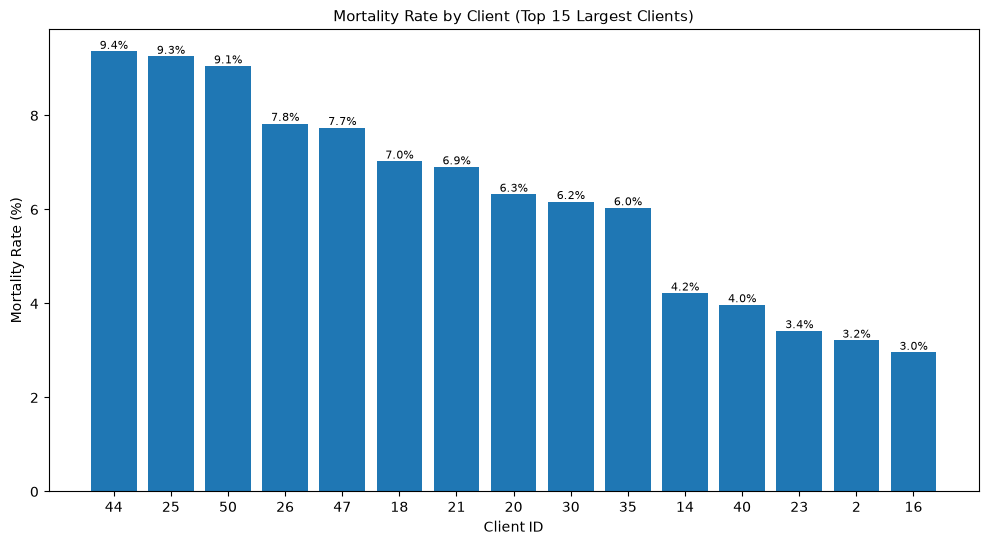

In [89]:
plt.figure(figsize=(12,6))

bars = plt.bar(
    top15_mortality['client_id'].astype(str),
    top15_mortality['Mortality_%']
)

plt.title('Mortality Rate by Client (Top 15 Largest Clients)')
plt.xlabel('Client ID')
plt.ylabel('Mortality Rate (%)')

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.show()

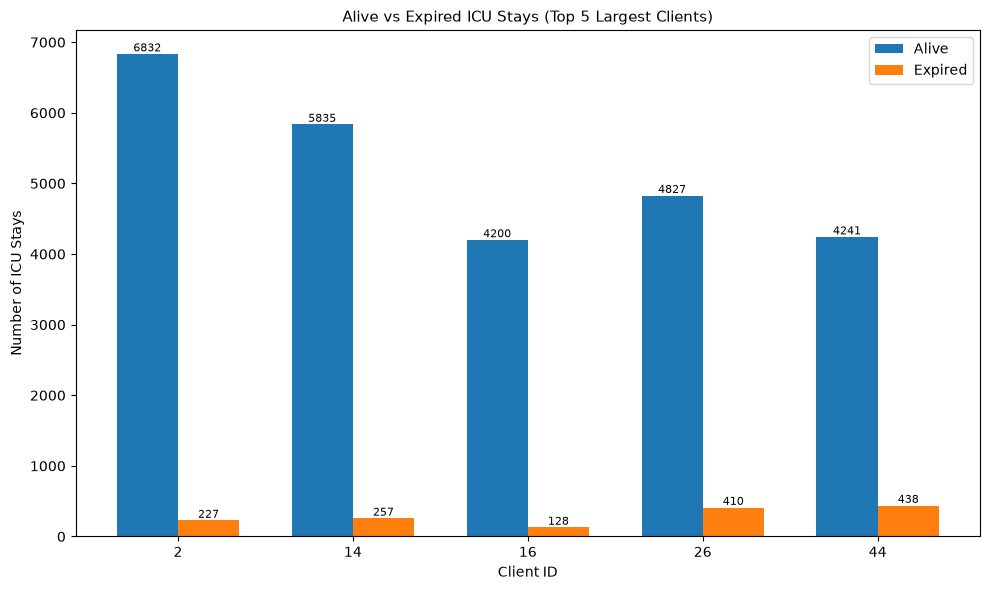

In [90]:
# Top 5 largest clients
top5_ids = (
    top15_clients
    .head(5)['client_id']
)

top5_data = (
    client_class_dist[
        client_class_dist['client_id']
        .isin(top5_ids)
    ]
    .sort_values(
        'client_id'
    )
)

x = np.arange(
    len(top5_data)
)

width = 0.35

plt.figure(figsize=(10,6))

bars1 = plt.bar(
    x - width/2,
    top5_data['Alive'],
    width,
    label='Alive'
)

bars2 = plt.bar(
    x + width/2,
    top5_data['Expired'],
    width,
    label='Expired'
)

plt.title(
    'Alive vs Expired ICU Stays (Top 5 Largest Clients)'
)

plt.xlabel(
    'Client ID'
)

plt.ylabel(
    'Number of ICU Stays'
)

plt.xticks(
    x,
    top5_data['client_id']
)

plt.legend()

# Alive labels
for bar in bars1:

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom',
        fontsize=8
    )

# Expired labels
for bar in bars2:

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.tight_layout()

plt.show()

# Step 1 — Prepare X and y

In [91]:
# Features and target
features = [
    'gender', 'age', 'ethnicity', 'apacheadmissiondx',
    'admissionheight', 'admissionweight', 'hospitaladmitoffset',
    'hospitaladmitsource', 'unittype', 'unitadmitsource',
    'unitvisitnumber', 'unitstaytype'
]

target = 'target'

X = df_fl[features]
y = df_fl[target]

# Step 2 — Global Train/Test Split

In [92]:
X_train_global, X_test_global, y_train_global, y_test_global = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [93]:
# Check patient-level overlap

train_patient_ids = set(
    df_fl.loc[X_train_global.index, 'patientunitstayid']
)

test_patient_ids = set(
    df_fl.loc[X_test_global.index, 'patientunitstayid']
)

overlap = train_patient_ids.intersection(test_patient_ids)

print("Unique patients in training:", len(train_patient_ids))
print("Unique patients in test:", len(test_patient_ids))
print("Patients appearing in both:", len(overlap))

Unique patients in training: 106027
Unique patients in test: 26507
Patients appearing in both: 0


# Step 3 — Create NON-IID Clients

In [94]:
# Example: group by hospital ID
clients = {}

for cid, group in df_fl.loc[X_train_global.index].groupby('hospitalid'):
    clients[cid] = {
        'X': group[features],
        'y': group[target]
    }

print("Total clients:", len(clients))

Total clients: 50


# Step 4 — Encode Categorical Features (GLOBAL)

In [95]:
X_train_encoded = pd.get_dummies(
    X_train_global,
    drop_first=True
)

X_test_encoded = pd.get_dummies(
    X_test_global,
    drop_first=True
)

# Align test with train
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join='left',
    axis=1,
    fill_value=0
)

print(X_train_encoded.shape, X_test_encoded.shape)

(106027, 445) (26507, 445)


# Step 5 — Encode Each Client

In [96]:
clients_encoded = {}

for cid in clients:

    X_client = pd.get_dummies(
        clients[cid]['X'],
        drop_first=True
    )

    X_client = X_client.reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    )

    clients_encoded[cid] = {
        'X': X_client,
        'y': clients[cid]['y']
    }

# Step 6 — Scaling (FIT ONLY ON GLOBAL TRAIN)

In [97]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

# Scale clients
clients_scaled = {}

for cid in clients_encoded:

    X_scaled = scaler.transform(clients_encoded[cid]['X'])

    clients_scaled[cid] = {
        'X': X_scaled,
        'y': clients_encoded[cid]['y'].values
    }

# Step 7 — Convert Clients to DataLoaders

In [98]:
client_loaders = {}
client_sizes = {}

for cid in clients_scaled:

    X_tensor = torch.tensor(
        clients_scaled[cid]['X'],
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        clients_scaled[cid]['y'],
        dtype=torch.float32
    ).view(-1, 1)

    dataset = TensorDataset(X_tensor, y_tensor)

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=True
    )

    client_loaders[cid] = loader
    client_sizes[cid] = len(y_tensor)

# Step 8 — Define Global MLP Model

In [99]:
import torch.nn as nn
import torch.nn.functional as F


class MLP(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

input_dim = X_train_scaled.shape[1]

global_model = MLP(input_dim)

# Step 9 — Local Training Function

In [100]:
import copy
import torch.optim as optim

def local_train(global_model, loader, epochs=1):

    local_model = copy.deepcopy(global_model)

    criterion = nn.BCELoss()
    optimizer = optim.Adam(local_model.parameters(), lr=0.001)

    local_model.train()

    for _ in range(epochs):
        for X_batch, y_batch in loader:

            optimizer.zero_grad()

            outputs = local_model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

    return local_model.state_dict()

# Step 10 — Weighted FedAvg

In [101]:
def weighted_fedavg(local_weights, client_sizes):

    total_samples = sum(client_sizes)

    avg_weights = {}

    for key in local_weights[0].keys():

        avg_weights[key] = sum(
            local_weights[i][key] * client_sizes[i]
            for i in range(len(local_weights))
        ) / total_samples

    return avg_weights

# Step 11 — Federated Training Loop

In [102]:
import copy

num_rounds = 20

all_round_global_weights_before = []
all_round_global_weights = []
all_round_local_weights = []

for r in range(num_rounds):

    print(f"Round {r+1}")

    # BEFORE update
    all_round_global_weights_before.append(
        copy.deepcopy(global_model.state_dict())
    )

    local_weights = []
    round_local_weights = []
    sizes = []

    for cid in client_loaders:

        weights = local_train(
            global_model,
            client_loaders[cid],
            epochs=1
        )

        local_weights.append(weights)
        sizes.append(client_sizes[cid])

        # save each client weight
        round_local_weights.append(
            copy.deepcopy(weights)
        )

    # weighted aggregation
    global_weights = weighted_fedavg(local_weights, sizes)

    global_model.load_state_dict(global_weights)

    # AFTER update
    all_round_global_weights.append(
        copy.deepcopy(global_weights)
    )

    # save all clients for this round
    all_round_local_weights.append(
        round_local_weights
    )

Round 1


/usr/local/lib/python3.11/dist-packages/torch/autograd/graph.py:882: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 34: CUDA driver is a stub library (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Round 2
Round 3
Round 4
Round 5
Round 6
Round 7
Round 8
Round 9
Round 10
Round 11
Round 12
Round 13
Round 14
Round 15
Round 16
Round 17
Round 18
Round 19
Round 20


# Step 12 — Evaluate on GLOBAL TEST SET

In [107]:
global_model.eval()

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

with torch.no_grad():
    y_prob = global_model(X_test_tensor).cpu().numpy().flatten()

auc = roc_auc_score(y_test_global, y_prob)

print("Non-IID Federated ROC-AUC:", auc)

Non-IID Federated ROC-AUC: 0.7446206929242012


In [108]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_test_global,
    y_prob
)

# Compute F1 score
f1_scores = 2 * precision * recall / (precision + recall + 1e-10)

# Find best threshold
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print("Best Threshold:", best_threshold)
print("Best F1 Score:", best_f1)

Best Threshold: 0.20812269
Best F1 Score: 0.2758379887769005


In [136]:
y_pred = (y_prob >= best_threshold).astype(int)


In [137]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test_global,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9564    0.9609    0.9586     25016
           1     0.2877    0.2649    0.2758      1491

    accuracy                         0.9218     26507
   macro avg     0.6220    0.6129    0.6172     26507
weighted avg     0.9188    0.9218    0.9202     26507



In [112]:
iid_auc = 0.7651885489463806
non_iid_auc = 0.7446206929242012

print("\nModel Comparison (ROC-AUC)\n")
print("{:<30} {:>10}".format("Setup", "AUC"))
print("-" * 42)
print("{:<30} {:>10.3f}".format("Federated IID (MLP)", iid_auc))
print("{:<30} {:>10.3f}".format("Federated Non-IID (MLP)", non_iid_auc))


Model Comparison (ROC-AUC)

Setup                                 AUC
------------------------------------------
Federated IID (MLP)                 0.765
Federated Non-IID (MLP)             0.745


In [ ]:
import pickle

artifacts = {
    "clients_scaled": clients_scaled,
    "clients": clients,
    "X_test_scaled": X_test_scaled,
    "y_test_global": y_test_global,
    "all_round_global_weights_before": all_round_global_weights_before,
    "all_round_global_weights": all_round_global_weights,
    "all_round_local_weights": all_round_local_weights
}

with open("fl_artifacts_non_iid.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Artifacts saved successfully")